# Predictive Maintenance - Final Project Notebook
**Capstone Project 3 | ManjunathaNS**

This executed notebook supports the final report. It covers data registration, EDA, data preparation, model experimentation, automation evidence and Streamlit deployment preparation.

Dataset source: AI4I 2020 Predictive Maintenance Dataset, UCI Machine Learning Repository, https://doi.org/10.24432/C5HS5C.

## 1. Data Registration

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
ROOT = Path('..').resolve()
DATA_DIR = ROOT / 'data'
FIG_DIR = ROOT / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_csv(DATA_DIR / 'ai4i2020.csv')
expected = ['UDI','Product ID','Type','Air temperature [K]','Process temperature [K]',
            'Rotational speed [rpm]','Torque [Nm]','Tool wear [min]','Machine failure',
            'TWF','HDF','PWF','OSF','RNF']
missing = [c for c in expected if c not in df_raw.columns]
assert not missing, f'Missing columns: {missing}'
print(f'Registered dataset: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns')
print('Duplicate rows:', df_raw.duplicated().sum())
print('Missing values:', int(df_raw.isna().sum().sum()))
print('Failure rate: {:.2%}'.format(df_raw['Machine failure'].mean()))
df_raw.head()

Registered dataset: 10000 rows x 14 columns
Duplicate rows: 0
Missing values: 0
Failure rate: 3.39%


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
summary = pd.DataFrame({'dtype': df_raw.dtypes.astype(str), 'missing': df_raw.isna().sum(), 'unique': df_raw.nunique()})
summary

,dtype,missing,unique
UDI,int64,0,10000
Product ID,str,0,10000
Type,str,0,3
Air temperature [K],float64,0,93
Process temperature [K],float64,0,82
Rotational speed [rpm],int64,0,941
Torque [Nm],float64,0,577
Tool wear [min],int64,0,246
Machine failure,int64,0,2
TWF,int64,0,2


## 2. Exploratory Data Analysis

/var/folders/lz/ssrnxfpj4gx46r7d7fy3h6fm0000gq/T/ipykernel_21458/3154888082.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Type', data=df_raw, ax=axes.flat[-1], palette='viridis')


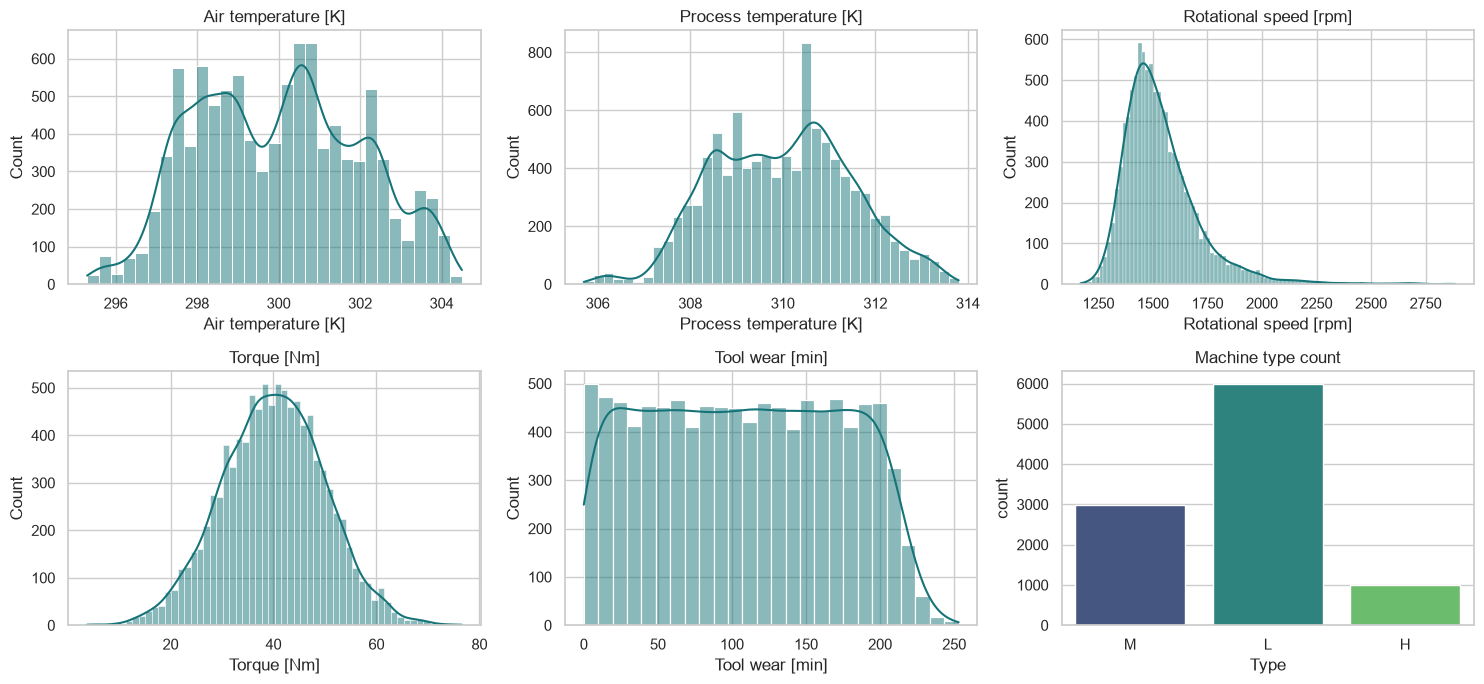

In [3]:
num_cols = ['Air temperature [K]','Process temperature [K]','Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df_raw[col], kde=True, ax=ax, color='#167478')
    ax.set_title(col)
sns.countplot(x='Type', data=df_raw, ax=axes.flat[-1], palette='viridis')
axes.flat[-1].set_title('Machine type count')
plt.tight_layout(); plt.savefig(FIG_DIR / 'final_univariate.png', dpi=140); plt.show()

/var/folders/lz/ssrnxfpj4gx46r7d7fy3h6fm0000gq/T/ipykernel_21458/1179519811.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Machine failure', y=col, data=df_raw, ax=ax, palette='Set2')
/var/folders/lz/ssrnxfpj4gx46r7d7fy3h6fm0000gq/T/ipykernel_21458/1179519811.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Machine failure', y=col, data=df_raw, ax=ax, palette='Set2')
/var/folders/lz/ssrnxfpj4gx46r7d7fy3h6fm0000gq/T/ipykernel_21458/1179519811.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Machine failure', y=col, data=df

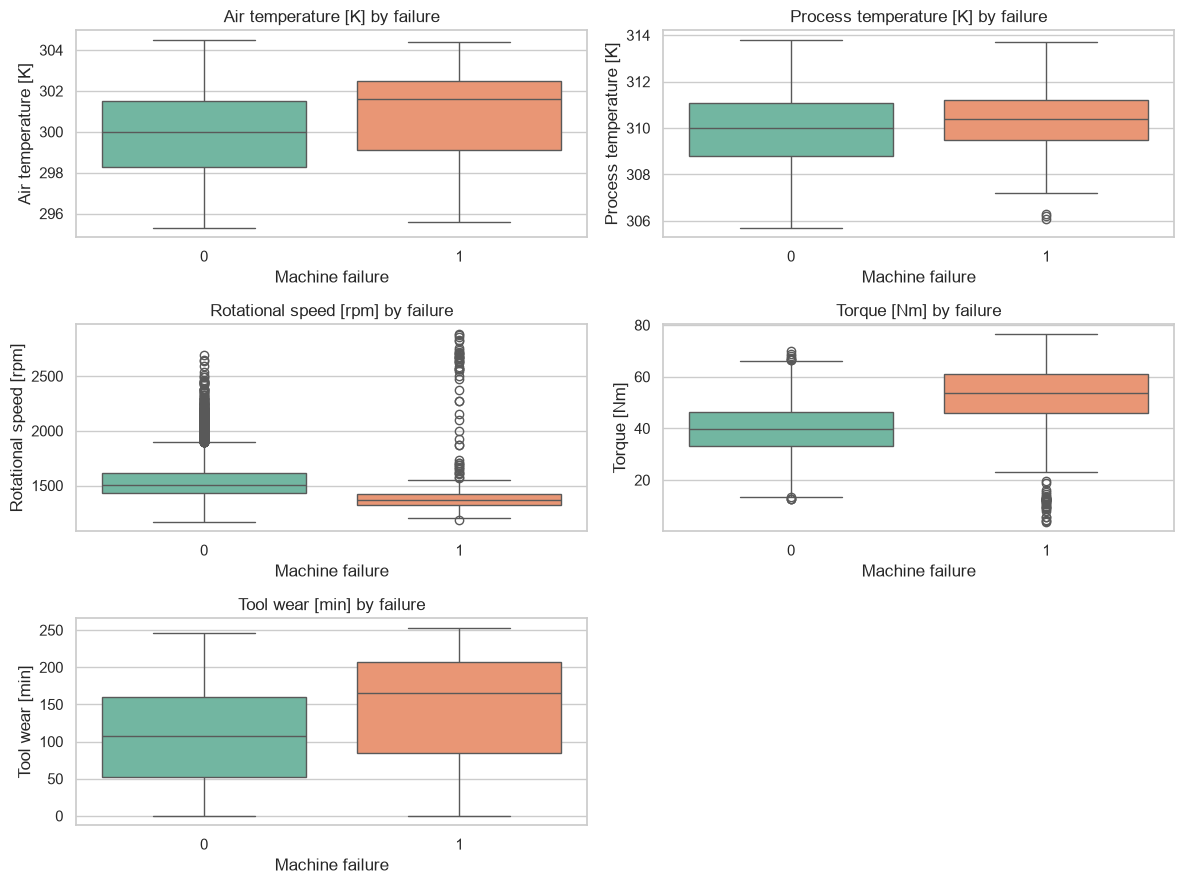

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(x='Machine failure', y=col, data=df_raw, ax=ax, palette='Set2')
    ax.set_title(f'{col} by failure')
axes.flat[-1].axis('off')
plt.tight_layout(); plt.savefig(FIG_DIR / 'final_bivariate.png', dpi=140); plt.show()

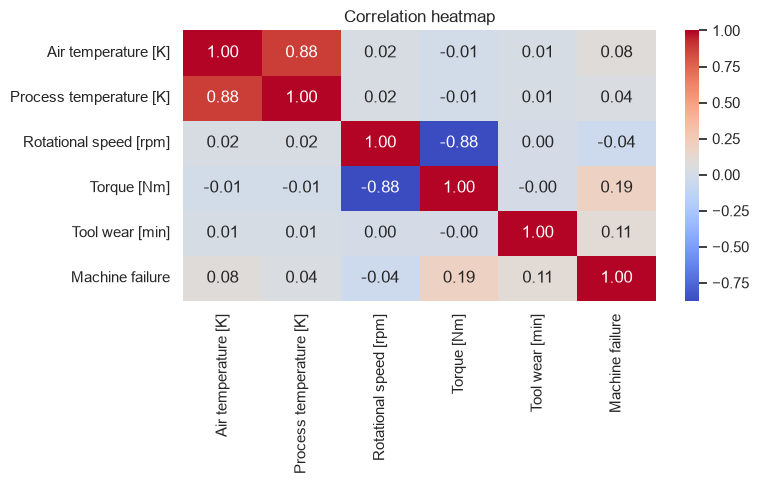

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(df_raw[num_cols + ['Machine failure']].corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=ax)
ax.set_title('Correlation heatmap')
plt.tight_layout(); plt.savefig(FIG_DIR / 'final_correlation.png', dpi=140); plt.show()

In [6]:
fail_by_type = df_raw.groupby('Type')['Machine failure'].agg(['count','sum','mean'])
fail_by_type['failure_rate_%'] = (fail_by_type['mean'] * 100).round(2)
fail_by_type[['count','sum','failure_rate_%']]

,count,sum,failure_rate_%
Type,,,
H,1003,21,2.09
L,6000,235,3.92
M,2997,83,2.77


### EDA observations
- Failures are rare (3.39%), so F1/recall are more meaningful than raw accuracy.
- Type L is the largest population and has the highest observed failure rate in this dataset.
- Temperature variables are correlated; sensor interpretation should consider multicollinearity.
- Operational risk should be scored from multiple sensor readings rather than a single threshold.

## 3. Data Preparation

In [7]:
from sklearn.model_selection import train_test_split

DROP_COLS = ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
df = df_raw.drop_duplicates().dropna().drop(columns=DROP_COLS)
df.columns = [c.split(' [')[0].replace(' ', '_') for c in df.columns]
TARGET = 'Machine_failure'
train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df[TARGET])
df.to_csv(DATA_DIR / 'cleaned.csv', index=False)
train.to_csv(DATA_DIR / 'train.csv', index=False)
test.to_csv(DATA_DIR / 'test.csv', index=False)
print('Cleaned:', df.shape, 'Train:', train.shape, 'Test:', test.shape)
print('Train failure rate:', round(train[TARGET].mean(), 4), 'Test failure rate:', round(test[TARGET].mean(), 4))
df.head()

Cleaned: (10000, 7) Train: (8000, 7) Test: (2000, 7)
Train failure rate: 0.0339 Test failure rate: 0.034


,Type,Air_temperature,Process_temperature,Rotational_speed,Torque,Tool_wear,Machine_failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


## 4. Model Building and Experimentation Tracking

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), X_train.select_dtypes(include=[np.number]).columns.tolist()),
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['Type']),
])
models = {
    'decision_tree': (DecisionTreeClassifier(random_state=42), {'model__max_depth':[3,5,8,None], 'model__min_samples_split':[2,10]}),
    'bagging': (BaggingClassifier(random_state=42, n_jobs=-1), {'model__n_estimators':[50,100], 'model__max_samples':[0.7,1.0]}),
    'random_forest': (RandomForestClassifier(random_state=42, n_jobs=-1), {'model__n_estimators':[100,200], 'model__max_depth':[5,10,None]}),
    'adaboost': (AdaBoostClassifier(random_state=42), {'model__n_estimators':[50,100], 'model__learning_rate':[0.5,1.0]}),
    'gradient_boosting': (GradientBoostingClassifier(random_state=42), {'model__n_estimators':[100,200], 'model__max_depth':[3,5], 'model__learning_rate':[0.05,0.1]}),
    'xgboost': (XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1), {'model__n_estimators':[100,200], 'model__max_depth':[3,5], 'model__learning_rate':[0.05,0.1]}),
}
log, best_name, best_cv, best_model = {}, None, -1, None
for name, (model, grid) in models.items():
    search = GridSearchCV(Pipeline([('prep', preprocessor), ('model', model)]), grid, cv=5, scoring='f1', n_jobs=-1)
    search.fit(X_train, y_train)
    preds = search.predict(X_test)
    proba = search.predict_proba(X_test)[:, 1]
    record = {
        'search_space': {k.replace('model__',''): v for k, v in grid.items()},
        'best_params': {k.replace('model__',''): v for k, v in search.best_params_.items()},
        'cv_best_f1': round(float(search.best_score_), 4),
        'test_accuracy': round(float(accuracy_score(y_test, preds)), 4),
        'test_precision': round(float(precision_score(y_test, preds)), 4),
        'test_recall': round(float(recall_score(y_test, preds)), 4),
        'test_f1': round(float(f1_score(y_test, preds)), 4),
        'test_roc_auc': round(float(roc_auc_score(y_test, proba)), 4),
        'confusion_matrix': confusion_matrix(y_test, preds).tolist(),
    }
    log[name] = record
    print(name, record)
    if record['cv_best_f1'] > best_cv:
        best_name, best_cv, best_model = name, record['cv_best_f1'], search.best_estimator_
log['_best_model'] = best_name

decision_tree {'search_space': {'max_depth': [3, 5, 8, None], 'min_samples_split': [2, 10]}, 'best_params': {'max_depth': 8, 'min_samples_split': 2}, 'cv_best_f1': 0.7007, 'test_accuracy': 0.9845, 'test_precision': 0.8364, 'test_recall': 0.6765, 'test_f1': 0.748, 'test_roc_auc': 0.8743, 'confusion_matrix': [[1923, 9], [22, 46]]}


bagging {'search_space': {'n_estimators': [50, 100], 'max_samples': [0.7, 1.0]}, 'best_params': {'max_samples': 1.0, 'n_estimators': 100}, 'cv_best_f1': 0.776, 'test_accuracy': 0.9865, 'test_precision': 0.8596, 'test_recall': 0.7206, 'test_f1': 0.784, 'test_roc_auc': 0.9666, 'confusion_matrix': [[1924, 8], [19, 49]]}


random_forest {'search_space': {'n_estimators': [100, 200], 'max_depth': [5, 10, None]}, 'best_params': {'max_depth': None, 'n_estimators': 200}, 'cv_best_f1': 0.6565, 'test_accuracy': 0.9815, 'test_precision': 0.8974, 'test_recall': 0.5147, 'test_f1': 0.6542, 'test_roc_auc': 0.9721, 'confusion_matrix': [[1928, 4], [33, 35]]}


adaboost {'search_space': {'n_estimators': [50, 100], 'learning_rate': [0.5, 1.0]}, 'best_params': {'learning_rate': 1.0, 'n_estimators': 100}, 'cv_best_f1': 0.4772, 'test_accuracy': 0.973, 'test_precision': 0.6667, 'test_recall': 0.4118, 'test_f1': 0.5091, 'test_roc_auc': 0.9553, 'confusion_matrix': [[1918, 14], [40, 28]]}


gradient_boosting {'search_space': {'n_estimators': [100, 200], 'max_depth': [3, 5], 'learning_rate': [0.05, 0.1]}, 'best_params': {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}, 'cv_best_f1': 0.7433, 'test_accuracy': 0.9865, 'test_precision': 0.8727, 'test_recall': 0.7059, 'test_f1': 0.7805, 'test_roc_auc': 0.9675, 'confusion_matrix': [[1925, 7], [20, 48]]}


xgboost {'search_space': {'n_estimators': [100, 200], 'max_depth': [3, 5], 'learning_rate': [0.05, 0.1]}, 'best_params': {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}, 'cv_best_f1': 0.7463, 'test_accuracy': 0.9865, 'test_precision': 0.8868, 'test_recall': 0.6912, 'test_f1': 0.7769, 'test_roc_auc': 0.9765, 'confusion_matrix': [[1926, 6], [21, 47]]}


In [9]:
MODEL_DIR = ROOT / 'models'; MODEL_DIR.mkdir(exist_ok=True)
(MODEL_DIR / 'metrics.json').write_text(json.dumps(log, indent=2))
joblib.dump(best_model, MODEL_DIR / 'best_model.joblib')
results = pd.DataFrame({k:v for k,v in log.items() if not k.startswith('_')}).T
results[['cv_best_f1','test_accuracy','test_precision','test_recall','test_f1','test_roc_auc']].sort_values('cv_best_f1', ascending=False)

,cv_best_f1,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
bagging,0.776,0.9865,0.8596,0.7206,0.784,0.9666
xgboost,0.7463,0.9865,0.8868,0.6912,0.7769,0.9765
gradient_boosting,0.7433,0.9865,0.8727,0.7059,0.7805,0.9675
decision_tree,0.7007,0.9845,0.8364,0.6765,0.748,0.8743
random_forest,0.6565,0.9815,0.8974,0.5147,0.6542,0.9721
adaboost,0.4772,0.973,0.6667,0.4118,0.5091,0.9553


/var/folders/lz/ssrnxfpj4gx46r7d7fy3h6fm0000gq/T/ipykernel_21458/3957957238.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results.reset_index().rename(columns={'index':'model'}), x='test_f1', y='model', palette='mako', ax=ax)


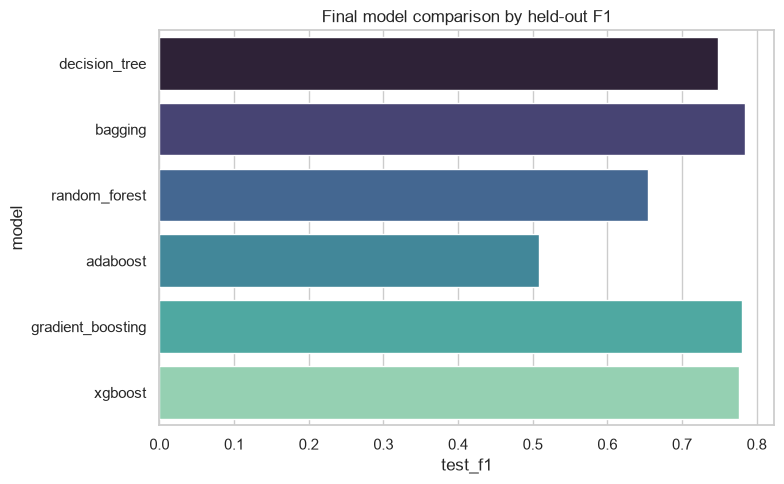

Best model: bagging


              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.86      0.72      0.78        68

    accuracy                           0.99      2000
   macro avg       0.92      0.86      0.89      2000
weighted avg       0.99      0.99      0.99      2000



In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=results.reset_index().rename(columns={'index':'model'}), x='test_f1', y='model', palette='mako', ax=ax)
ax.set_title('Final model comparison by held-out F1')
plt.tight_layout(); plt.savefig(FIG_DIR / 'final_model_comparison.png', dpi=140); plt.show()
print('Best model:', best_name)
print(classification_report(y_test, best_model.predict(X_test)))

## 5. Deployment and Automation Evidence

In [11]:
from pathlib import Path
checks = {
    'Streamlit app exists': (ROOT / 'app.py').exists(),
    'Model exists': (ROOT / 'models' / 'best_model.joblib').exists(),
    'Requirements exists': (ROOT / 'requirements.txt').exists(),
    'Workflow exists': (ROOT / '.github' / 'workflows' / 'pipeline.yml').exists(),
}
checks

{'Streamlit app exists': True,
 'Model exists': True,
 'Requirements exists': True,
 'Workflow exists': True}

In [12]:
sample_input = pd.DataFrame([{
    'Type': 'L', 'Air_temperature': 298.8, 'Process_temperature': 309.8,
    'Rotational_speed': 1500, 'Torque': 40.0, 'Tool_wear': 100,
}])
loaded = joblib.load(ROOT / 'models' / 'best_model.joblib')
print('Sample input dataframe:')
display(sample_input)
print('Predicted failure probability:', round(float(loaded.predict_proba(sample_input)[0][1]), 4))

Sample input dataframe:


,Type,Air_temperature,Process_temperature,Rotational_speed,Torque,Tool_wear
0,L,298.8,309.8,1500,40.0,100


Predicted failure probability: 0.0


## 6. Actionable Recommendations
- Use model scores as an inspection prioritisation tool, not an autonomous shutdown decision.
- Track recall and missed failures after deployment because missed breakdowns are costly.
- Re-train on real production data and compare performance by machine type.
- Add monitoring for data drift in temperature, torque, speed and tool-wear distributions.
- Review the alert threshold with maintenance teams based on false-alarm cost versus downtime cost.